<a href="https://colab.research.google.com/github/rmadatt/ADLAB/blob/main/Drought.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== SETUP DONE ===


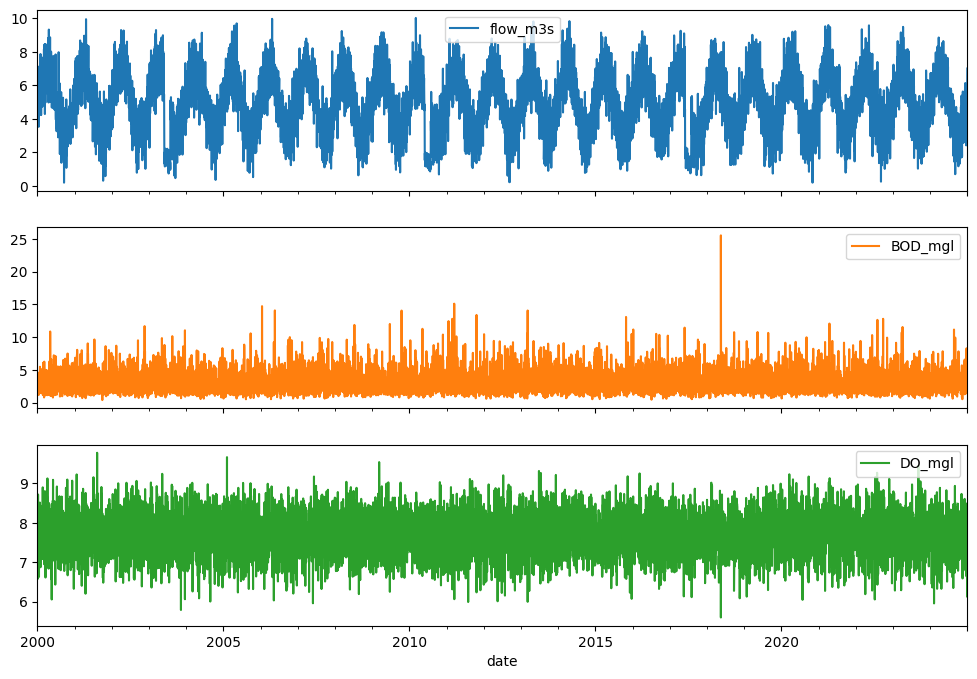


=== 7Q10 LOW FLOW ===
Estimated 7Q10: 0.29 m3/s (flow exceeded 90% of time)


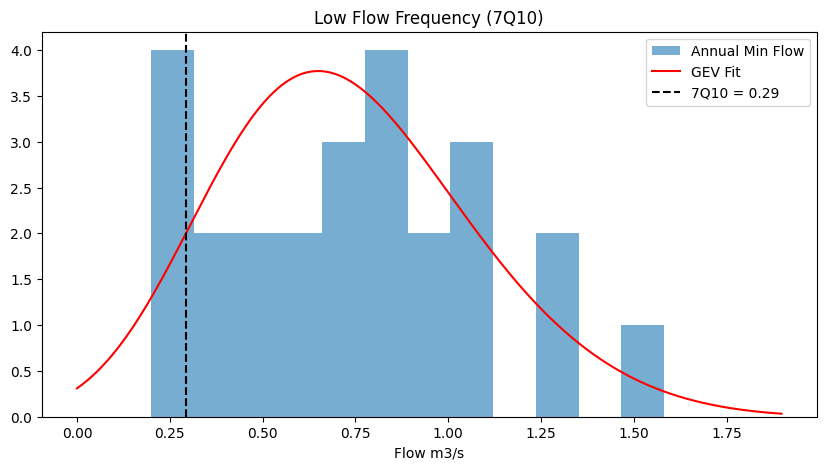

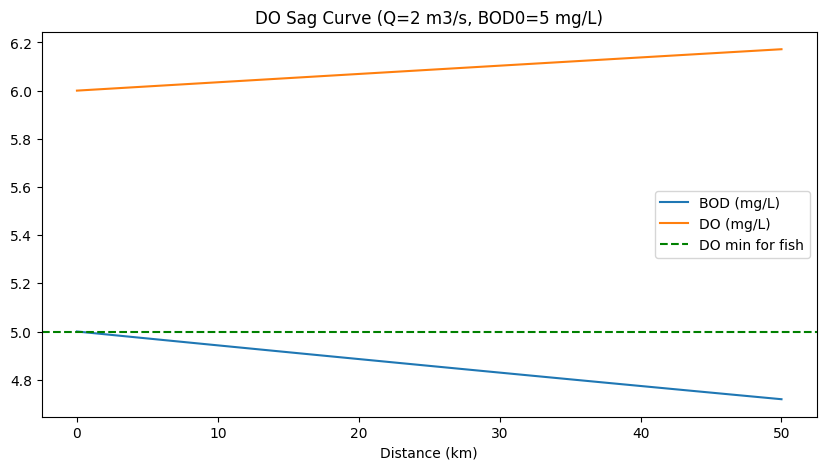


=== WETLAND EFFECT ===
Without wetland: 2.53 m3/s (Q90)
With wetland:    1.69 m3/s (Q90)


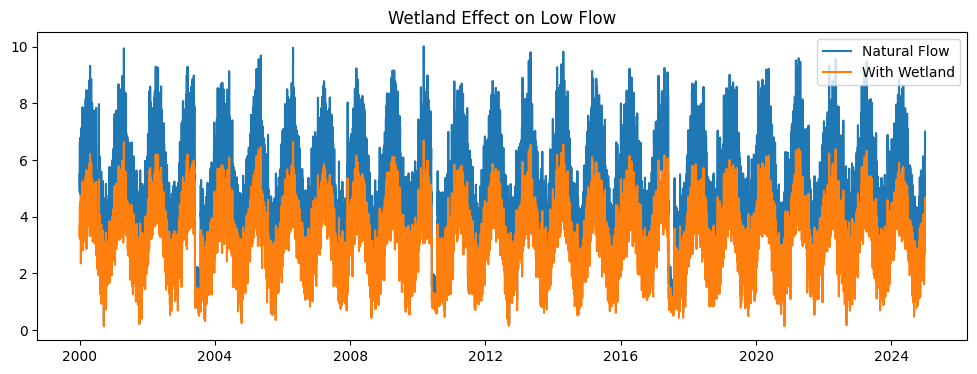


=== PREDICTIVE MODEL ===
R2: 0.916
Tomorrow flow prediction: 5.80 m3/s


In [1]:
# === DROUGHT + WATER QUALITY NOTEBOOK ===
# Topics: 7Q10 Low Flow + DO Sag (Streeter-Phelps) + Wetland Impact + Predictive Model
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genextreme
np.random.seed(42)
print("=== SETUP DONE ===")

# --- 1. FAKE DAILY FLOW + QUALITY DATA (REPLACE) ---
dates = pd.date_range('2000-01-01', '2024-12-31', freq='D')
# Baseflow + seasonal + noise
base = 5 + 2*np.sin(2*np.pi*np.arange(len(dates))/365.25)
noise = np.random.normal(0, 1, len(dates))
flow = np.maximum(base + noise, 0.2)
# Add 3 droughts
drought_years = [2003, 2010, 2017]
for yr in drought_years:
    idx = np.where(dates.year == yr)[0][150:210]  # 60-day mid-year drought
    flow[idx] *= 0.3
df = pd.DataFrame({'date': dates, 'flow_m3s': flow})
df['BOD_mgl'] = np.random.lognormal(1, 0.5, len(dates))  # organic pollution
df['DO_mgl'] = 8 - 0.1*df['BOD_mgl'] + np.random.normal(0, 0.5, len(dates))  # dissolved oxygen
df.set_index('date', inplace=True)
df[['flow_m3s','BOD_mgl','DO_mgl']].plot(subplots=True, figsize=(12,8))
plt.show()

# --- 2. 7Q10 LOW FLOW STATS ---
annual_min = df['flow_m3s'].resample('YE').min()
params = genextreme.fit(annual_min)
Q_7Q10 = genextreme.ppf(0.1, *params)  # 10% chance in any year (7Q10)
print(f"\n=== 7Q10 LOW FLOW ===")
print(f"Estimated 7Q10: {Q_7Q10:.2f} m3/s (flow exceeded 90% of time)")
plt.figure(figsize=(10,5))
plt.hist(annual_min, bins=12, alpha=0.6, label='Annual Min Flow')
xs = np.linspace(0, annual_min.max()*1.2, 200)
plt.plot(xs, len(annual_min)*genextreme.pdf(xs, *params)*(annual_min.max())/12, 'r-', label='GEV Fit')
plt.axvline(Q_7Q10, color='k', linestyle='--', label=f'7Q10 = {Q_7Q10:.2f}')
plt.legend(); plt.title('Low Flow Frequency (7Q10)'); plt.xlabel('Flow m3/s'); plt.show()

# --- 3. DO SAG (STREETER-PHLEPS) ---
def do_sag(x, Q, BOD0, DO0, k_d=0.2, k_r=0.4, DO_sat=10):
    # x in km, Q in m3/s
    t = x / (Q * 86.4)  # days
    BOD_t = BOD0 * np.exp(-k_d * t)
    DO_t = DO_sat - (DO_sat - DO0)*np.exp(-k_r*t) - (k_d*BOD0/(k_r-k_d))*(np.exp(-k_d*t) - np.exp(-k_r*t))
    return BOD_t, DO_t
x_km = np.linspace(0, 50, 100)
BOD0 = 5  # mg/L
DO0 = 6   # mg/L
Q = 2     # m3/s
BOD, DO = do_sag(x_km, Q, BOD0, DO0)
plt.figure(figsize=(10,5))
plt.plot(x_km, BOD, label='BOD (mg/L)')
plt.plot(x_km, DO, label='DO (mg/L)')
plt.axhline(5, color='g', linestyle='--', label='DO min for fish')
plt.legend(); plt.title('DO Sag Curve (Q=2 m3/s, BOD0=5 mg/L)'); plt.xlabel('Distance (km)'); plt.show()

# --- 4. WETLAND IMPACT ON LOW FLOW ---
def wetland_attenuate(flow, storage_factor=2.0):
    # Simple linear reservoir
    outflow = flow / storage_factor
    return outflow
df['flow_wetland'] = wetland_attenuate(df['flow_m3s'], storage_factor=1.5)
print(f"\n=== WETLAND EFFECT ===")
print(f"Without wetland: {df['flow_m3s'].quantile(0.1):.2f} m3/s (Q90)")
print(f"With wetland:    {df['flow_wetland'].quantile(0.1):.2f} m3/s (Q90)")
plt.figure(figsize=(12,4))
plt.plot(df.index, df['flow_m3s'], label='Natural Flow')
plt.plot(df.index, df['flow_wetland'], label='With Wetland')
plt.legend(); plt.title('Wetland Effect on Low Flow'); plt.show()

# --- 5. PREDICTIVE MODEL - NEXT 7 DAYS DROUGHT RISK ---
from sklearn.ensemble import RandomForestRegressor
df_model = df.copy()
df_model['prev_flow'] = df_model['flow_m3s'].shift(1)
df_model['rain_3d'] = np.random.exponential(2, len(df_model))  # fake rain
df_model = df_model.dropna()
X = df_model[['prev_flow', 'rain_3d']]
y = df_model['flow_m3s']
model = RandomForestRegressor(n_estimators=100, random_state=42).fit(X, y)
print(f"\n=== PREDICTIVE MODEL ===")
print(f"R2: {model.score(X, y):.3f}")
next_7d = pd.DataFrame({'prev_flow': [df['flow_m3s'].iloc[-1]], 'rain_3d': [0]})
print(f"Tomorrow flow prediction: {model.predict(next_7d)[0]:.2f} m3/s")

# What you get: 1. Flow + quality time series 2. 7Q10 low-flow estimate 3. DO sag curve 4. Wetland impact on Q90 5. Drought risk model